# Module 3 - Finding Data Sets

**Name:** Clement Scaccia  
**Course:** Data Visualization

For this assignment I picked one data set in each of the four categories: **personal, government, commercial, and learning**. All the files are in the `data` folder of this repository, one subfolder per category. For each one I explain where it comes from, what's in it, and why I picked it, then load it with pandas and make a quick chart to show what it looks like.

| Category | Data set | Source | File |
|---|---|---|---|
| Personal | PBA Men's Soccer 2026 season | PBA Athletics official stats | `data/personal/` |
| Government | US Consumer Price Index (CPI-U), monthly since 1913 | U.S. Bureau of Labor Statistics | `data/government/us_cpi_monthly_bls.csv` |
| Commercial | VIX volatility index, daily since 1990 | Cboe Global Markets | `data/commercial/cboe_vix_daily.csv` |
| Learning | Palmer Penguins | Palmer Station LTER, via palmerpenguins / seaborn | `data/learning/palmer_penguins.csv` |

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

DATA = "../data"
plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

## 1. Personal - PBA Men's Soccer 2026 Season

**Source:** PBA Athletics official cumulative stats for the 2026 season (as of Oct 28, 2026): https://s3.us-east-2.amazonaws.com/sidearm.nextgen.sites/palmbeach.sidearmsports.com/stats/msoc/2026/pdf/cume.pdf  
Team site: https://pbasailfish.com/

**Files:**
- `pba_mens_soccer_2026_results.csv`: all 16 games (date, opponent, home/away, result, score, attendance)
- `pba_mens_soccer_2026_player_stats.csv`: stats for every player (games played, goals, assists, shots, shots on goal, cards, game winners)

**How I got it:** there's no download or API, the stats are only in a PDF, so I copied the tables into CSV files myself. I checked the totals against the team totals in the PDF (28 goals for, 18 against, 204 shots, 90 shots on goal) and they match.

**Why I picked it:** I play on the team (#18), so this is literally my own season. It's a small data set, but it's one I actually understand, and I can ask real questions with it, like whether we play better at home than away (we're unbeaten at home and only won one game on the road) or how much our scoring depends on one player.

In [2]:
results = pd.read_csv(f"{DATA}/personal/pba_mens_soccer_2026_results.csv", parse_dates=["Date"])
players = pd.read_csv(f"{DATA}/personal/pba_mens_soccer_2026_player_stats.csv")
print(results.shape, players.shape)
results.head()

(16, 7) (28, 11)


,Date,Opponent,Location,Result,PBA_Goals,Opp_Goals,Attendance
0,2026-08-27,Lincoln Memorial,Home,W,2,0,113
1,2026-08-29,Carson-Newman,Home,T,2,2,105
2,2026-09-02,Young Harris,Away,T,1,1,100
3,2026-09-04,North Georgia,Neutral,L,0,2,238
4,2026-09-12,Emory & Henry,Away,T,0,0,37


In [3]:
# Record by location
pd.crosstab(results["Location"], results["Result"])

Result,L,T,W
Location,,,
Away,4,2,1
Home,0,3,5
Neutral,1,0,0


In [4]:
# My own line
players[players["Player"] == "Scaccia, Clement"]

,Number,Player,GP,G,A,PTS,SH,SOG,YC,RC,GW
12,18,"Scaccia, Clement",13,0,1,1,8,2,0,0,0


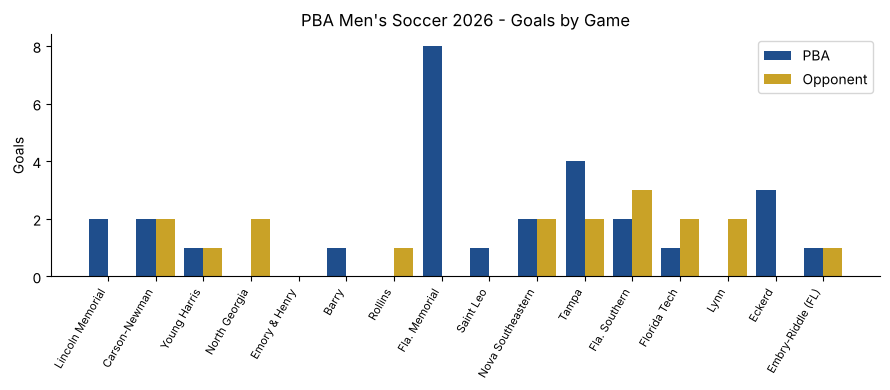

In [5]:
fig, ax = plt.subplots()
x = range(len(results))
ax.bar([i - 0.2 for i in x], results["PBA_Goals"], width=0.4, label="PBA", color="#1f4e8c")
ax.bar([i + 0.2 for i in x], results["Opp_Goals"], width=0.4, label="Opponent", color="#c9a227")
ax.set_xticks(list(x))
ax.set_xticklabels(results["Opponent"], rotation=60, ha="right", fontsize=8)
ax.set_ylabel("Goals")
ax.set_title("PBA Men's Soccer 2026 - Goals by Game")
ax.legend()
plt.tight_layout()
plt.show()

## 2. Government - US Consumer Price Index (BLS)

**Source:** U.S. Bureau of Labor Statistics, CPI for All Urban Consumers (CPI-U), U.S. city average, all items, 1982-84 = 100. https://www.bls.gov/cpi/  
I downloaded the CSV from the open data package on GitHub that pulls it from the BLS API and updates every month: https://github.com/datasets/cpi-us

**What's in it:** one row per month from January 1913 to September 2026. `Index` is the CPI level and `Inflation` is the month over month % change.

**How to get it:** direct CSV download from GitHub, or from the BLS website and the BLS public API (https://api.bls.gov/publicAPI/v2/timeseries/data/).

**Why I picked it:** with my finance background, inflation is one of the most important numbers in the economy, it affects interest rates, stock prices and company valuations. It's official government data so it's reliable, and having more than 100 years of it makes it great for time series charts.

In [6]:
cpi = pd.read_csv(f"{DATA}/government/us_cpi_monthly_bls.csv", parse_dates=["Date"])
cpi["YoY_Inflation_%"] = cpi["Index"].pct_change(12) * 100
print(cpi.shape)
cpi.tail()

(1364, 4)


,Date,Index,Inflation,YoY_Inflation_%
1359,2026-05-01,335.123,0.63,4.466404
1360,2026-06-01,333.952,-0.35,3.884404
1361,2026-07-01,333.918,-0.01,3.520884
1362,2026-08-01,334.980,0.32,3.693569
1363,2026-09-01,336.940,0.59,4.001531


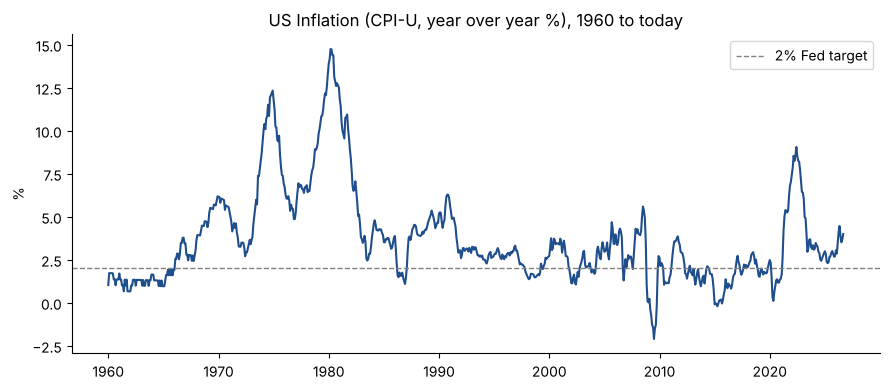

In [7]:
fig, ax = plt.subplots()
recent = cpi[cpi["Date"] >= "1960-01-01"]
ax.plot(recent["Date"], recent["YoY_Inflation_%"], color="#1f4e8c")
ax.axhline(2, color="gray", linestyle="--", linewidth=1, label="2% Fed target")
ax.set_title("US Inflation (CPI-U, year over year %), 1960 to today")
ax.set_ylabel("%")
ax.legend()
plt.tight_layout()
plt.show()

## 3. Commercial - Cboe VIX Volatility Index

**Source:** Cboe Global Markets (a private company that runs the Chicago Board Options Exchange). Official historical data page: https://www.cboe.com/tradable_products/vix/vix_historical_data/  
I downloaded the CSV from the open data package on GitHub that mirrors Cboe's file: https://github.com/datasets/finance-vix

**What's in it:** daily open, high, low and close of the VIX from January 1990 to September 2026 (about 9,000 rows). One thing to know: before mid-2004 Cboe only recorded the closing value, so open/high/low are just copies of the close for those years.

**Why I picked it:** the VIX is called the market's "fear gauge" because it measures how much volatility investors expect in the S&P 500 over the next 30 days. I follow the markets, and it's interesting to see the big spikes line up with real events like 2008 and COVID in 2020. It's also a good example of commercial data, since it's produced by a company and not the government.

In [8]:
vix = pd.read_csv(f"{DATA}/commercial/cboe_vix_daily.csv", parse_dates=["DATE"])
print(vix.shape)
print(vix["CLOSE"].describe().round(2))
vix.nlargest(5, "CLOSE")

(9278, 5)
count    9278.00
mean       19.43
std         7.72
min         9.14
25%        13.99
50%        17.58
75%        22.68
max        82.69
Name: CLOSE, dtype: float64


,DATE,OPEN,HIGH,LOW,CLOSE
7606,2020-03-16,57.83,83.56,57.83,82.69
4760,2008-11-20,74.26,81.48,72.76,80.86
4742,2008-10-27,79.13,81.65,71.29,80.06
4741,2008-10-24,67.80,89.53,67.80,79.13
7608,2020-03-18,69.37,85.47,69.37,76.45


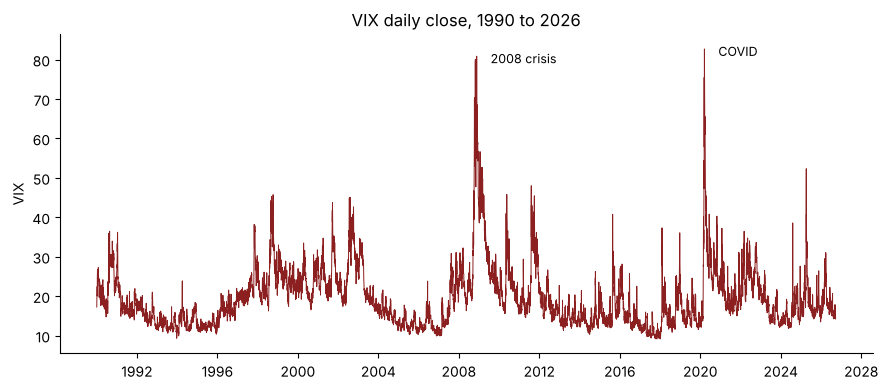

In [9]:
fig, ax = plt.subplots()
ax.plot(vix["DATE"], vix["CLOSE"], color="#8c1f1f", linewidth=0.7)
for date, label in [("2008-11-20", "2008 crisis"), ("2020-03-16", "COVID")]:
    row = vix[vix["DATE"] == date]
    if not row.empty:
        ax.annotate(label, (row["DATE"].iloc[0], row["CLOSE"].iloc[0]), xytext=(10, -5), textcoords="offset points", fontsize=9)
ax.set_title("VIX daily close, 1990 to 2026")
ax.set_ylabel("VIX")
plt.tight_layout()
plt.show()

## 4. Learning - Palmer Penguins

**Source:** data collected by Dr. Kristen Gorman at Palmer Station, Antarctica (Palmer Station LTER), released as the `palmerpenguins` package by Allison Horst, Alison Hill and Kristen Gorman: https://allisonhorst.github.io/palmerpenguins/  
I downloaded the CSV from the seaborn sample data repository: https://github.com/mwaskom/seaborn-data

**What's in it:** 344 penguins from 3 species (Adelie, Chinstrap, Gentoo) on 3 islands, with bill length, bill depth, flipper length, body mass and sex.

**Why I picked it:** it's made for learning. It's small and clean, but it still has a few missing values to practice with, and it has both categories (species, island, sex) and numbers, so you can practice almost every chart type: bar, scatter, histogram, box plot. A lot of people use it now instead of the old Iris data set.

In [10]:
peng = pd.read_csv(f"{DATA}/learning/palmer_penguins.csv")
print(peng.shape)
print("Missing values:")
print(peng.isna().sum())
peng.groupby("species")[["bill_length_mm", "flipper_length_mm", "body_mass_g"]].mean().round(1)

(344, 7)
Missing values:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64


,bill_length_mm,flipper_length_mm,body_mass_g
species,,,
Adelie,38.8,190.0,3700.7
Chinstrap,48.8,195.8,3733.1
Gentoo,47.5,217.2,5076.0


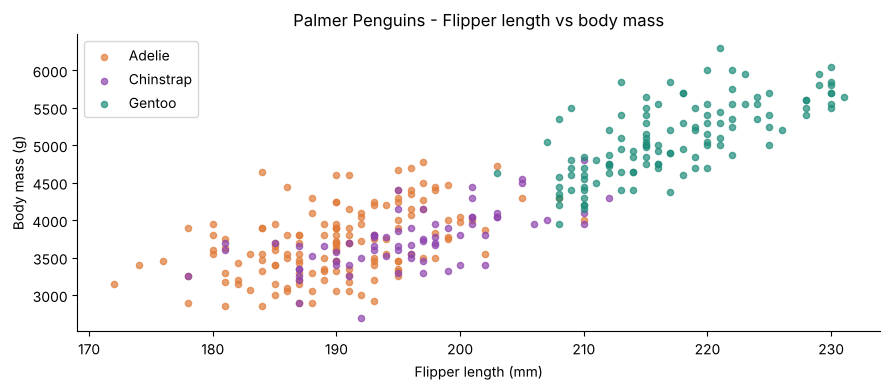

In [11]:
fig, ax = plt.subplots()
colors = {"Adelie": "#e07b39", "Chinstrap": "#8e44ad", "Gentoo": "#1f8c7a"}
for sp, g in peng.dropna().groupby("species"):
    ax.scatter(g["flipper_length_mm"], g["body_mass_g"], label=sp, alpha=0.7, s=20, color=colors[sp])
ax.set_xlabel("Flipper length (mm)")
ax.set_ylabel("Body mass (g)")
ax.set_title("Palmer Penguins - Flipper length vs body mass")
ax.legend()
plt.tight_layout()
plt.show()

## Summary

| Category | Rows | Time span | How I got it |
|---|---|---|---|
| Personal | 16 games, 28 players | 2026 season | copied from the official PDF into CSV |
| Government | ~1,360 months | 1913 to 2026 | CSV download (BLS data) |
| Commercial | ~9,300 days | 1990 to 2026 | CSV download (Cboe data) |
| Learning | 344 penguins | 2007 to 2009 | CSV download |

Each one is useful for something different. The personal data is small but it's the one I care about the most, the government and commercial ones are long time series that fit finance questions, and the penguins are the easiest one to practice new chart types on. Together they give me a good mix to use in the next modules.